In [2]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"
if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"



# INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory 
try:
    new_dir = pathlib.Path(FIG_DIR+'/Wind_Obs/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

try:
    new_dir = pathlib.Path(FIG_DIR+'/sf_class_frequ/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

try:
    new_dir = pathlib.Path(FIG_DIR+'/KDE_observations/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass


mimi.uio.no


## Import python packages

* `Python` environment requirements: file .txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [3]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [4]:
# import packages
from imports_geo_env import (np, plt, ccrs,  Point, gpd, xr, glob, pd, BoundaryNorm, cm, find_peaks, rasterio, from_bounds, set_context, Wedge, WindroseAxes, sns, LinearSegmentedColormap)
import functions_geo_env as fct



In [5]:
# reload imports
%load_ext autoreload
%autoreload 2

In [6]:

# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [7]:
# Define location of Campaign 2023
lon0, lat0 = 16.0337, 69.2955

# Define wind sectors
# angles = np.linspace(0, 360, 37)[:-1]
angles = np.linspace(0, 360, 73)[:-1]
radius = 0.09  # in degrees

# Load land shapes using GeoPandas (from Natural Earth shapefile)
# land_gdf = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# https://www.naturalearthdata.com/downloads/10m-physical-vectors/
land_gdf10 = gpd.read_file(f'{WORKDIR}/work/combined_obs/ne_10m_land/ne_10m_land.shp')

ocean_gdf = gpd.read_file(f'{WORKDIR}/work/combined_obs/ne_10m_ocean/ne_10m_ocean.shp')


# raster_file = f'{WORKDIR}/work/combined_obs/HYP_LR_SR/HYP_LR_SR.tif'
raster_file = f"{WORKDIR}/work/combined_obs/HYP_HR/HYP_HR.tif"

In [8]:
extent = [lon0 - 0.5, lon0 + 0.15, lat0 - 0.5, lat0 + 0.15]
extent = [lon0 - 1.5, lon0 + 1.5, lat0 - 2, lat0 + 1]

land_gdf10 = land_gdf10.cx[extent[0]:extent[1], extent[2]:extent[3]]
ocean_gdf = ocean_gdf.cx[extent[0]:extent[1], extent[2]:extent[3]]

In [9]:
results = []

# Compute rays and check intersection
for angle in angles:
    theta = np.deg2rad(angle) # Convert angle to radians
    lon1 = lon0 + radius * np.cos(theta) # Calculate endpoint longitude
    lat1 = lat0 + radius * np.sin(theta) # Calculate endpoint latitude
    # line = LineString([(lon0, lat0), (lon1, lat1)])
    endpoint = Point(lon1, lat1)
    
    # Check if the endpoint is within the land or ocean polygon
    within_land = land_gdf10.contains(endpoint).any()
    within_ocean = ocean_gdf.contains(endpoint).any()
    # meteorological_angle = (angle + 90) % 360
    meteorological_angle = (90 - angle) % 360

    # Print debugging information
    if angle in [0, 90, 180, 270]:
        print(f"Angle: {angle} - Met. Angle: {meteorological_angle}")# - Within land: {within_land} - Within ocean: {within_ocean}")
    
    # Classify the endpoint
    if within_land == True:
        results.append((angle, 'land', meteorological_angle))
    elif within_ocean == True:
        results.append((angle, 'ocean', meteorological_angle))
    else:
        results.append((angle, 'none', meteorological_angle))


Angle: 0.0 - Met. Angle: 90.0
Angle: 90.0 - Met. Angle: 0.0
Angle: 180.0 - Met. Angle: 270.0
Angle: 270.0 - Met. Angle: 180.0


In [10]:
# Find the index where the label switches from "ocean" to "land" or vice versa
switch_indices = []
for i in enumerate(results):
    prev_label = results[i[0] - 1][1] # Label of the previous result
    curr_label = results[i[0]][1] # Label of the current result
    if prev_label != curr_label: # Check if the label has switched
        print(f"Switch from {prev_label} to {curr_label} at index {i[0]} and angle {results[i[0]][2]}")
        switch_indices.append(i[0]) # Store the index of the switch

Switch from land to ocean at index 3 and angle 75.0
Switch from ocean to land at index 40 and angle 250.0


In [11]:
# Define the extent to crop to (min_lon, max_lon, min_lat, max_lat)
crop_extent = [lon0 - 2., lon0 + 2.5, lat0 - 2, lat0 + .5]


# Open the raster file
with rasterio.open(raster_file) as src:
    # Ensure the CRS matches WGS84 (EPSG:4326)
    if src.crs.to_string() != 'EPSG:4326':
        raise ValueError(f"Raster CRS ({src.crs}) does not match EPSG:4326!")

    # Create a window from the crop extent
    window = from_bounds(crop_extent[0], crop_extent[2], crop_extent[1], crop_extent[3], transform=src.transform)
    
    # Read the cropped data
    cropped_data = src.read(1, window=window)
    
    # Get the transform for the cropped data
    cropped_transform = src.window_transform(window)

# Generate coordinates for the cropped raster
x_coords = np.linspace(crop_extent[0], crop_extent[1], cropped_data.shape[1])
y_coords = np.linspace(crop_extent[3], crop_extent[2], cropped_data.shape[0])



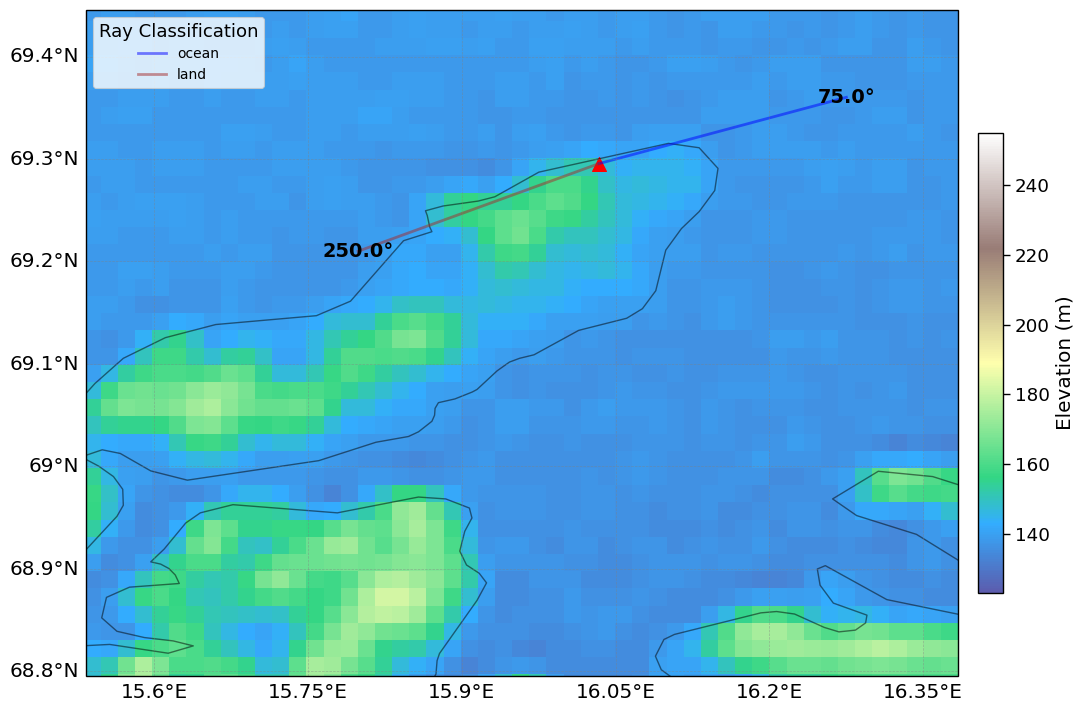

In [12]:
# Plot the cropped raster
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})

mesh = fct.add_base_map(ax, [lon0 - 0.5, lon0 + 0.35, lat0 - 0.5, lat0 + 0.15], x_coords, y_coords, cropped_data, land_gdf10, lon0, lat0)

# Add a colorbar
cbaxes = fig.add_axes([.99, 0.25, 0.025, 0.46])
cbar = plt.colorbar(mesh, cax=cbaxes, orientation='vertical', shrink=0.7, pad=0.05)
cbar.set_label('Elevation (m)')


# Set tick parameters to hide ticks on the top and right
fct.add_ray_directions(ax, lon0, lat0, results, switch_indices)
fct.add_gridlines(ax)

plt.tight_layout()


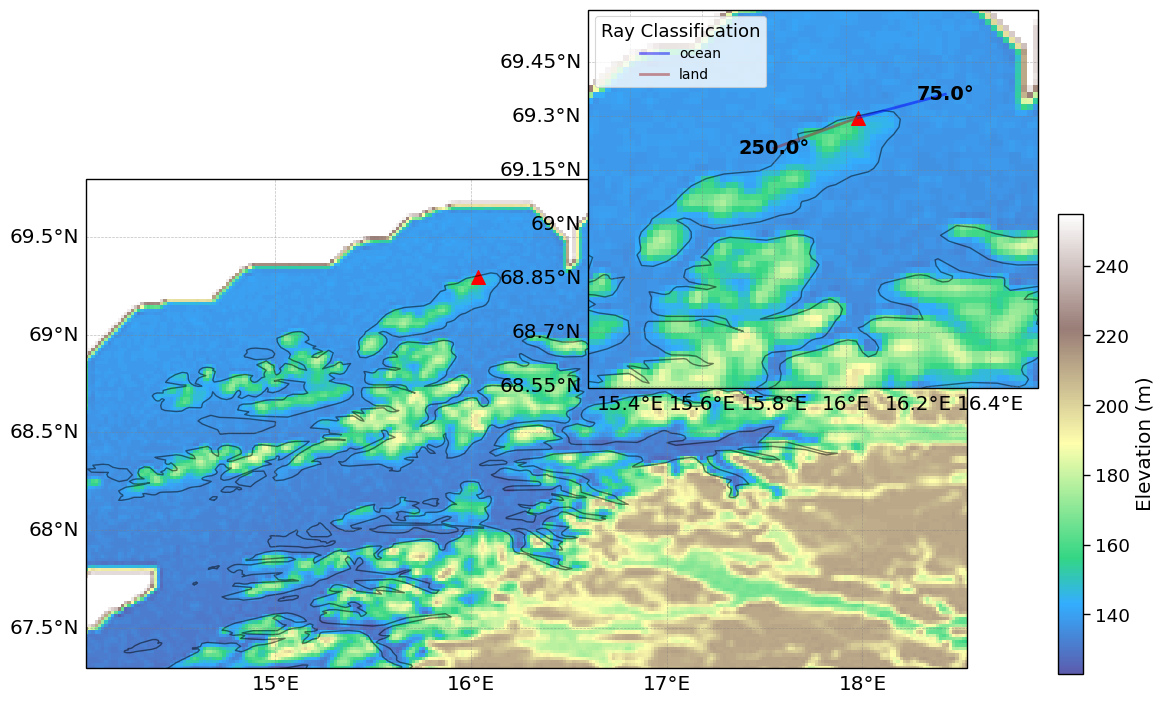

In [13]:

# Plot the main map
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})

mesh = fct.add_base_map(ax, [lon0 - 2., lon0 + 2.5, lat0 - 2, lat0 + .5], x_coords, y_coords, cropped_data, land_gdf10, lon0, lat0)

# Add a colorbar
cbaxes = fig.add_axes([1.07, 0.25, 0.025, 0.46])
cbar = plt.colorbar(mesh, cax=cbaxes, orientation='vertical', shrink=0.7, pad=0.05)
cbar.set_label('Elevation (m)')

fct.add_gridlines(ax)

# Add the inset map
inset_ax = plt.axes([0.6, 0.5, 0.45, 0.45], projection=ccrs.PlateCarree())  # Adjust position and size

mesh = fct.add_base_map(inset_ax, [lon0 - 0.75, lon0 + 0.5, lat0 - 0.75, lat0 + 0.3], x_coords, y_coords, cropped_data, land_gdf10, lon0, lat0)
fct.add_ray_directions(inset_ax, lon0, lat0, results, switch_indices)
fct.add_gridlines(inset_ax)

plt.tight_layout()
# plt.show()

# figname = f"Wind_Obs/land_see_wind_{round(lon0,2)}_{round(lat0,2)}.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [14]:
date_ranges = {
    # "2021": pd.date_range("2021-03-16", "2021-03-30").strftime("%Y%m%d").tolist(),
    # "2022": pd.date_range("2022-03-17", "2022-04-07").strftime("%Y%m%d").tolist(),
    "2023": pd.date_range("2023-02-12", "2023-03-14").strftime("%Y%m%d").tolist(),
}

In [17]:
dsx = {}
# use wind and temperature from Hatpro
dsx['HATPRO'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'obs_ANX_2023*.nc'))))
# use wind and temperature from airport data
dsx['Airport'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'obs_airport_*ANX_2023*.nc'))))

# Combine HATPRO temperature and Airport wind data
dsx['HATPRO_Airport'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'obs_hatpro_airport_*ANX_2023*.nc'))))

# Combine HATPRO 10 min averaged temperature and Airport 10 min wind data
dsx['HATPRO_Airport_10min'] = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'10min_filled_obs_hatpro_airport_*ANX_2023*.nc'))))
# substitute the wind direction and speed and remove the variable *_filled*
dsx['HATPRO_Airport_10min']['wind_direction'] = dsx['HATPRO_Airport_10min']['wind_direction_filled'].copy()
dsx['HATPRO_Airport_10min']['wind_speed'] = dsx['HATPRO_Airport_10min']['wind_speed_filled'].copy()
dsx['HATPRO_Airport_10min'] = dsx['HATPRO_Airport_10min'].drop_vars(["wind_direction_filled", "wind_speed_filled"])



In [18]:
# Define bins
wd_bins = np.arange(0, 361, 22.5)
ws_bins = np.arange(0, 21, 1)
at_bins = np.arange(-6,7,1)


# shading for land/ocean
shade_regions = [
        (results[switch_indices[0]][2], results[switch_indices[1]][2], 'sienna', 'Land'),
        (0, results[switch_indices[0]][2], 'dodgerblue', 'Ocean'),
        (results[switch_indices[1]][2], 360, 'dodgerblue', 'Ocean')
    ]

particle_vars = [
        'aggregate',
        # 'columnar_crystal',
        # 'columnar_planar_combination',
        'graupel',
        'pristine'
        # 'planar_crystal',
        # 'small_particle'
    ]
var_names = np.concatenate((np.array(['wind_direction', 'air_temperature', 'wind_speed', 'precipitation', 'Ze', 'W', 'spectralWidth', 'most_common_class']), np.array(particle_vars)))


wind_direction_ds = {}
wind_speed_ds = {}
air_temperature_ds = {}

In [19]:
bins_dict = {'wind_direction': wd_bins, 'wind_speed': ws_bins, 'air_temperature': at_bins}
xlims = {'wind_direction': [0, 360], 'wind_speed': [0,20], 'air_temperature': [-6,6]}
ylims = {'wind_direction': [0,0.015], 'wind_speed': [0, 0.22], 'air_temperature': [0,0.16]}
var_units = {'wind_direction': '°', 'wind_speed': 'm/s', 'air_temperature': '°C',}
vlines = [results[switch_indices[0]][2], results[switch_indices[1]][2]]


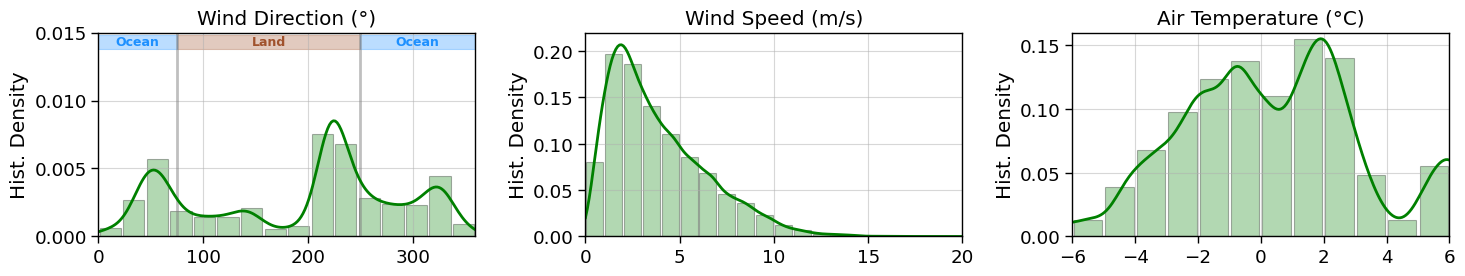

In [20]:
fig, axsm = plt.subplots(1, 3, figsize=(15, 3), )
axs = axsm.flatten()

fct.plt_variable_group(axs, {'HATPRO': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature'])},  ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'HATPRO':'green', }, labels={'HATPRO': 'HATPRO',}, xlims=xlims, ylims=ylims, kde=True, shade_regions=shade_regions, var_units=var_units, vlines=vlines)


plt.tight_layout()
# figname = f"KDE_observations/KDE_WD_WS_AT_ANX_2023.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

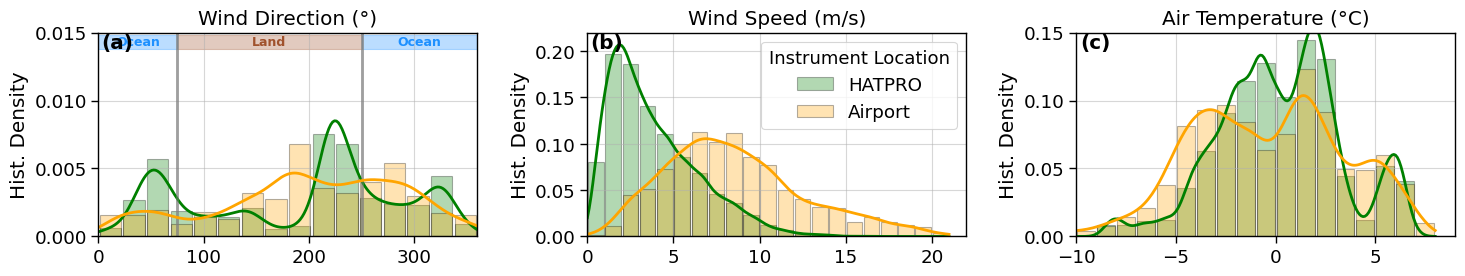

In [21]:
bins_dict = {'wind_direction': wd_bins, 'wind_speed': np.arange(0,22), 'air_temperature': np.arange(-10,9,1)}
xlims = {'wind_direction': [0, 360], 'wind_speed': [0,22], 'air_temperature': [-10,9]}
ylims = {'wind_direction': [0,0.015], 'wind_speed': [0, 0.22], 'air_temperature': [0,0.15]}




# Data dicts by condition
data_dict = {
    'HATPRO': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature']),
    'Airport': fct.extract_clean_data(dsx['Airport'], ['wind_direction', 'wind_speed', 'air_temperature']),
    'combined': fct.extract_clean_data(dsx['HATPRO_Airport_10min'], ['wind_direction', 'wind_speed', 'air_temperature'])
}

fig, axsm = plt.subplots(1, 3, figsize=(15, 3), )
axs = axsm.flatten()

fct.plt_variable_group(axs,{'HATPRO': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature'])}, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'HATPRO':'green', }, labels={'HATPRO': 'HATPRO', }, xlims=xlims, ylims=ylims, kde=True, shade_regions=shade_regions, var_units=var_units,  vlines=vlines)

fct.plt_variable_group(axs,{'Airport': fct.extract_clean_data(dsx['Airport'], ['wind_direction', 'wind_speed', 'air_temperature'])}, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'HATPRO':'green', 'Airport': 'orange', 'Combined': 'red'}, labels={'HATPRO': 'HATPRO', 'Airport':'Airport', 'Combined':'Combined'}, xlims=xlims, ylims=ylims, kde=True,  var_units=var_units,  vlines=vlines, legend_title='Instrument Location',)



# fct.kde_results = fct.plt_variable_group(axs,{'Combined': fct.extract_clean_data(dsx['hatpro_airport_10min'], ['wind_direction', 'wind_speed', 'air_temperature'])}, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'HATPRO':'green', 'Airport': 'orange', 'Combined': 'red'}, labels={'HATPRO': 'HATPRO', 'Airport':'Airport', 'Combined':'Combined'}, xlims=xlims, ylims=ylims, kde=True,  var_units=var_units,  vlines=vlines, legend_title='Instrument Location',)

for i, ax in enumerate(axs):
    ax.text(0.05, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

plt.tight_layout()

# figname = f"KDE_observations/KDE_WD_WS_AT_hatpro_airport.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

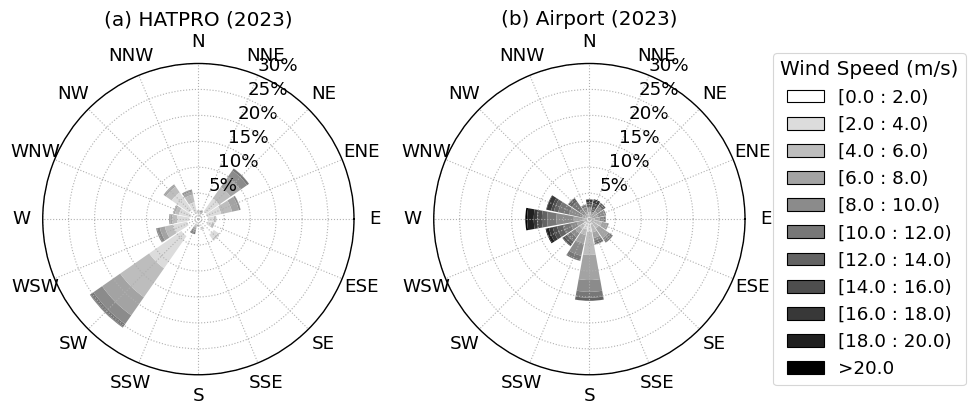

In [40]:
## Compare HATPRO vs. airport wind data


hatpro = fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed',], mask=None)

airport = fct.extract_clean_data(dsx['Airport'], ['wind_direction', 'wind_speed',], mask=None)


direction_labels = ['E',  'ENE',  'NE', 'NNE', 'N', 'NNW', 'NW', 'WNW', 'W', 'WSW', 'SW', 'SSW', 'S', 'SSE', 'SE', 'ESE', ]

fig, axsm = plt.subplots(1,2, figsize=(10,6), subplot_kw=dict(projection="windrose"))
# cmap=cm.hawaii
cmap = cm.grayC_r
bins = np.arange(0,22,2)
normed = True

axsm[0].bar(hatpro['wind_direction'], hatpro['wind_speed'], bins=bins, normed=normed, cmap=cmap,  opening=0.9, edgecolor=None,)
axsm[1].bar(airport['wind_direction'], airport['wind_speed'], bins=bins, normed=normed, cmap=cmap, opening=0.9, edgecolor=None,)

for ax, (i, title) in zip(axsm.flatten(), enumerate(["HATPRO (2023)", "Airport (2023)",])):
    ax.set_title(f"{fct.fig_label[i]} {title}")
    # Set consistent radial ticks
    ax.set_yticks([5, 10, 15, 20, 25, 30])
    ax.set_yticklabels(['5%', '10%', '15%', '20%', '25%', '30%'])
    # ax.set_theta_zero_location('N') # 0° is at the top (North)
    # ax.set_theta_direction(-1) # Make angles increase clockwise
    ax.set_thetagrids(np.arange(0, 360, 22.5), labels=direction_labels)
    ax.grid(True, ls=':')
    

    
# Create one shared legend from the last axes
axsm[-1].legend(loc='center left', title='Wind Speed (m/s)', bbox_to_anchor=(1.06, 0.5))
plt.tight_layout()
figname = f"Wind_Obs/windrose_hatpro_airport.png"
plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

In [20]:
# --- Apply conditioning

for loc in dsx.keys():
    # if loc == 'HATPRO_Airport_10min':
    #     wind_id = 'wind_direction_filled'
    # else:
    #     wind_id = 'wind_direction'
    wind_id = 'wind_direction'
    # Compute the boolean indexer for land/ocean wind first
    land_condition = ((dsx[loc][wind_id] >= results[switch_indices[0]][2]) & 
                      (dsx[loc][wind_id] < results[switch_indices[1]][2])).compute()


    # Compute the boolean indexer for ocean
    ocean_condition = ((dsx[loc][wind_id] >= results[switch_indices[1]][2]) | 
                       (dsx[loc][wind_id] < results[switch_indices[0]][2])).compute()

    # Compute the boolean indexer for air temperature first
    warm_condition = (dsx[loc]['air_temperature'] >= -2.).compute()
    cold_condition = (dsx[loc]['air_temperature'] < -2.).compute()
    
    # Reprocess temperature categories (use e.g., 25th /75th percentile)
    q25_temp = dsx[loc]['air_temperature'].quantile(q=0.25, dim='time', keep_attrs =True, skipna=True).values
    q75_temp = dsx[loc]['air_temperature'].quantile(q=0.75, dim='time', keep_attrs =True, skipna=True).values
    print(f"{loc}: Temperature 25th percentile = {q25_temp:.2f}, 75th percentile ={q75_temp:.2f}")
    # Compute the boolean indexer for air temperature first
    q75_condition = (dsx[loc]['air_temperature'] >= q75_temp).compute()
    q25_condition = (dsx[loc]['air_temperature'] <= q25_temp).compute()
    
    for var in var_names:
        if var in dsx[loc]:
            dsx[loc][var+'_land'] = dsx[loc][var].where(land_condition, drop=True)
            dsx[loc][var+'_ocean'] = dsx[loc][var].where(ocean_condition, drop=True)
            
            dsx[loc][var+'_cold'] = dsx[loc][var].where(cold_condition, drop=True)
            dsx[loc][var+'_warm'] = dsx[loc][var].where(warm_condition, drop=True)
            
            dsx[loc][var+'_q25'] = dsx[loc][var].where(q25_condition, drop=True)
            dsx[loc][var+'_q75'] = dsx[loc][var].where(q75_condition, drop=True)
            
            # print(f"{loc}, {var}, All: {dsx[loc][var].count().values}, Land: {dsx[loc][var+'_land'].count().values}, Ocean: {dsx[loc][var+'_ocean'].count().values}, Cold: {dsx[loc][var+'_cold'].count().values}, Warm: {dsx[loc][var+'_warm'].count().values}")




HATPRO: Temperature 25th percentile = -1.68, 75th percentile =2.59
Airport: Temperature 25th percentile = -3.30, 75th percentile =2.30
HATPRO_Airport: Temperature 25th percentile = -1.68, 75th percentile =2.59
HATPRO_Airport_10min: Temperature 25th percentile = -1.68, 75th percentile =2.59


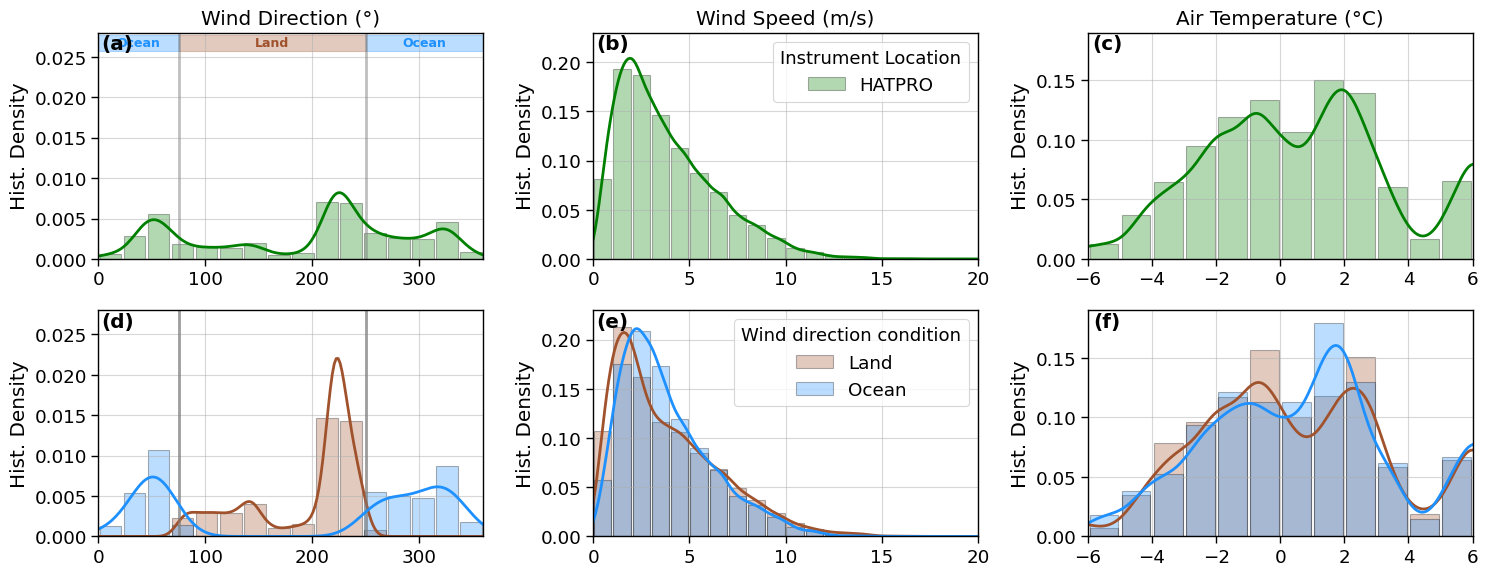

In [21]:
bins_dict = {'wind_direction': wd_bins, 'wind_speed': ws_bins, 'air_temperature': at_bins}
xlims = {'wind_direction': [0, 360], 'wind_speed': [0,20], 'air_temperature': [-6,6]}
ylims = {'wind_direction': [0,0.028], 'wind_speed': [0, 0.23], 'air_temperature': [0,0.19]}


fig, axsm = plt.subplots(2, 3, figsize=(15, 6), )
axs = axsm.flatten()

fct.plt_variable_group(axs[0:3],{'HATPRO': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature']),}, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'HATPRO':'green'}, labels={'HATPRO': 'HATPRO'}, xlims=xlims, ylims=ylims, kde=True, shade_regions=shade_regions, var_units=var_units, legend_title='Instrument Location', vlines=vlines, show_titles=True)


# Data dicts by condition
data_dict = {
    'land': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction_land', 'wind_speed_land', 'air_temperature_land']),
    'ocean': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction_ocean', 'wind_speed_ocean', 'air_temperature_ocean'])
}
fct.plt_variable_group(axs[3:6], data_dict, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'land':'sienna', 'ocean':'dodgerblue'}, labels={'land':'Land', 'ocean':'Ocean'}, xlims=xlims, ylims=ylims, kde=True,  legend_title ='Wind direction condition', vlines=vlines, var_units=var_units, show_titles=False)

for i, ax in enumerate(axs):
    ax.text(0.05, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

plt.tight_layout()


# figname = f"KDE_observations/KDE_WD_WS_AT_land_ocean.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)


In [22]:
df_sf_class = {}
for loc in dsx.keys():
    df_sf_class[loc] = pd.DataFrame([], columns=['all', 'land', 'ocean'], index=particle_vars)
    for sf_class in particle_vars:
        # df_sf_class[loc]['all'][sf_class] = float(dsx[loc][sf_class].sum(dim='time',skipna=True).compute())
        # df_sf_class[loc]['land'][sf_class] = float(dsx[loc][sf_class+'_land'].sum(dim='time',skipna=True).compute())
        # df_sf_class[loc]['ocean'][sf_class] = float(dsx[loc][sf_class+'_ocean'].sum(dim='time',skipna=True).compute())
        df_sf_class[loc]['all'][sf_class] = float(dsx[loc]['most_common_class'].where((dsx[loc]['most_common_class'] == sf_class).compute()).count(dim='time').compute())
        df_sf_class[loc]['land'][sf_class] = float(dsx[loc]['most_common_class_land'].where((dsx[loc]['most_common_class_land'] == sf_class).compute()).count(dim='time').compute())
        df_sf_class[loc]['ocean'][sf_class] = float(dsx[loc]['most_common_class_ocean'].where((dsx[loc]['most_common_class_ocean'] == sf_class).compute()).count(dim='time').compute())

    # Calculate total sum of all land points
    df_sf_class[loc].loc['total'] = df_sf_class[loc].sum(axis=0)
    print(f"total occurence of land points {loc}: {df_sf_class[loc].loc['total']['land']}, of ocean points: {df_sf_class[loc].loc['total']['ocean']}")

    # relative frequency conditioned on the wind direction (normalized by the number of land/ocean points)
    # Given ocean/land wind, what is the probability of each snowflake type?
    df_sf_class[loc]['relative_land'] = df_sf_class[loc]['land'] / df_sf_class[loc].loc['total']['land']
    df_sf_class[loc]['relative_ocean'] = df_sf_class[loc]['ocean'] / df_sf_class[loc].loc['total']['ocean']

for loc in dsx.keys():
    df_sf_class[loc].reset_index(inplace=True)
    df_sf_class[loc].rename(columns={'index': 'sf_class'}, inplace=True)

total occurence of land points HATPRO: 1334.0, of ocean points: 1024.0
total occurence of land points Airport: 183.0, of ocean points: 171.0
total occurence of land points HATPRO_Airport: 183.0, of ocean points: 171.0
total occurence of land points HATPRO_Airport_10min: 1876.0, of ocean points: 1624.0


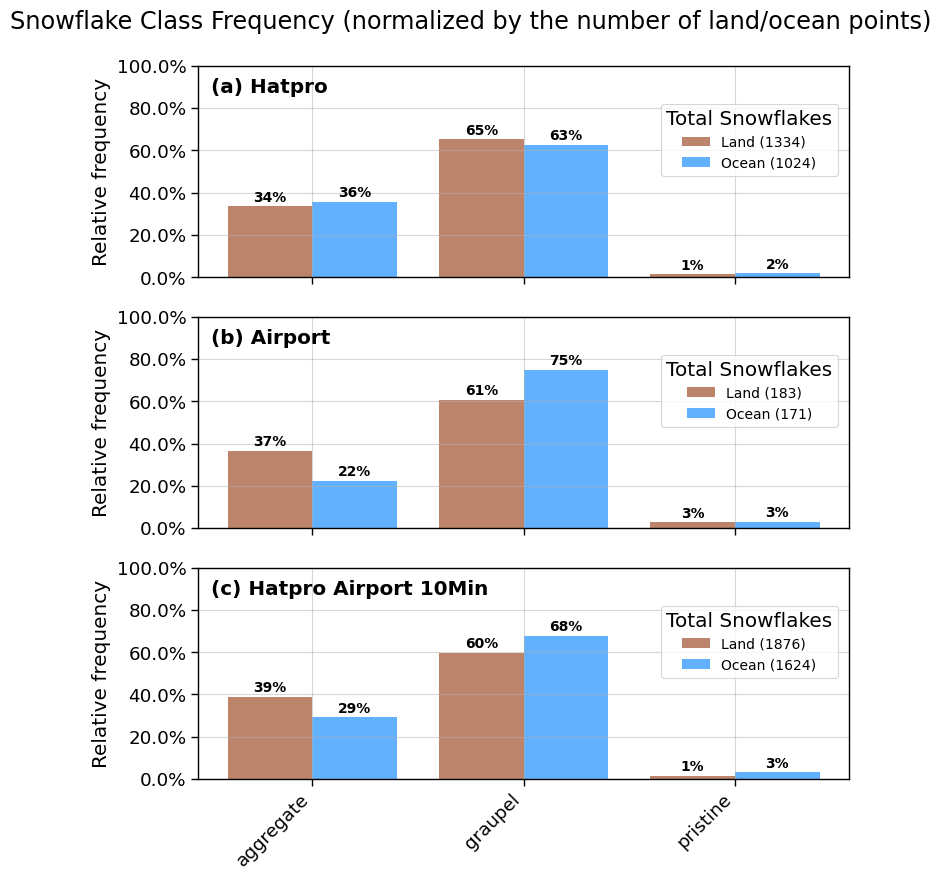

In [23]:
fig, axsm = plt.subplots(3,1, figsize=(8,9), sharex=True, sharey=True)
fig.suptitle(f"Snowflake Class Frequency (normalized by the number of land/ocean points)", )
fig.subplots_adjust(top=0.94)

for ax, loc, i in zip(axsm.flatten(), ['HATPRO', 'Airport', 'HATPRO_Airport_10min'], range(len(fct.fig_label))):
    
    ax.text(0.02, 0.9, f"{fct.fig_label[i]} {loc.replace('_', ' ').title()}", fontweight='bold', horizontalalignment='left', verticalalignment='center', transform=ax.transAxes)
    # Set ticks
    ax.set_yticks(np.arange(0,1.1,0.2))
    ax.set_yticklabels(f"{x:.1%}" for x in np.arange(0,1.1,0.2))
    ax.set_ylabel("Relative frequency")
    ax.set_ylim([0, 1])
    ax.set_xticks(np.arange(len(df_sf_class[loc].index)))
    ax.set_xticklabels(df_sf_class[loc]['sf_class'], rotation=45, ha='right')
    ax.grid(alpha=0.5)

    ax.bar(df_sf_class[loc].index[:-1]-0.2, df_sf_class[loc]['relative_land'][:-1], width= 0.4, color='sienna', label=f"Land ({df_sf_class[loc].iloc[-1]['land']:.0f})", alpha=0.7)
    ax.bar(df_sf_class[loc].index[:-1]+0.2, df_sf_class[loc]['relative_ocean'][:-1], width= 0.4, color='dodgerblue', label=f"Ocean ({df_sf_class[loc].iloc[-1]['ocean']:.0f})", alpha=0.7)

    # Add text labels from the 'all' column on top of the first bar for each group
    for i, val in enumerate(df_sf_class[loc]['relative_land'][:-1]):
        ax.text(
            i - 0.2,  # x position (adjust for bar alignment)
            max(df_sf_class[loc].loc[i, ['relative_land', ]]) + 0.01,  # y position above the bar
            f"{val:.0%}",  # format as integer
            ha='center', va='bottom', fontsize=10, color='black', fontweight='bold'
        )
    for i, val in enumerate(df_sf_class[loc]['relative_ocean'][:-1]):
        ax.text(
            i + 0.2,  # x position (adjust for bar alignment)
            max(df_sf_class[loc].loc[i, ['relative_ocean', ]]) + 0.01,  # y position above the bar
            f"{val:.0%}",  # format as integer
            ha='center', va='bottom', fontsize=10, color='black', fontweight='bold'
        )
    
    ax.legend( loc='center left',bbox_to_anchor=(0.7, 0.65), fontsize=10, frameon=True, markerscale=1.5,title="Total Snowflakes", )#title_fontsize='13', ,

plt.tight_layout()

# figname = f"Wind_Obs/sf_class_frequency.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

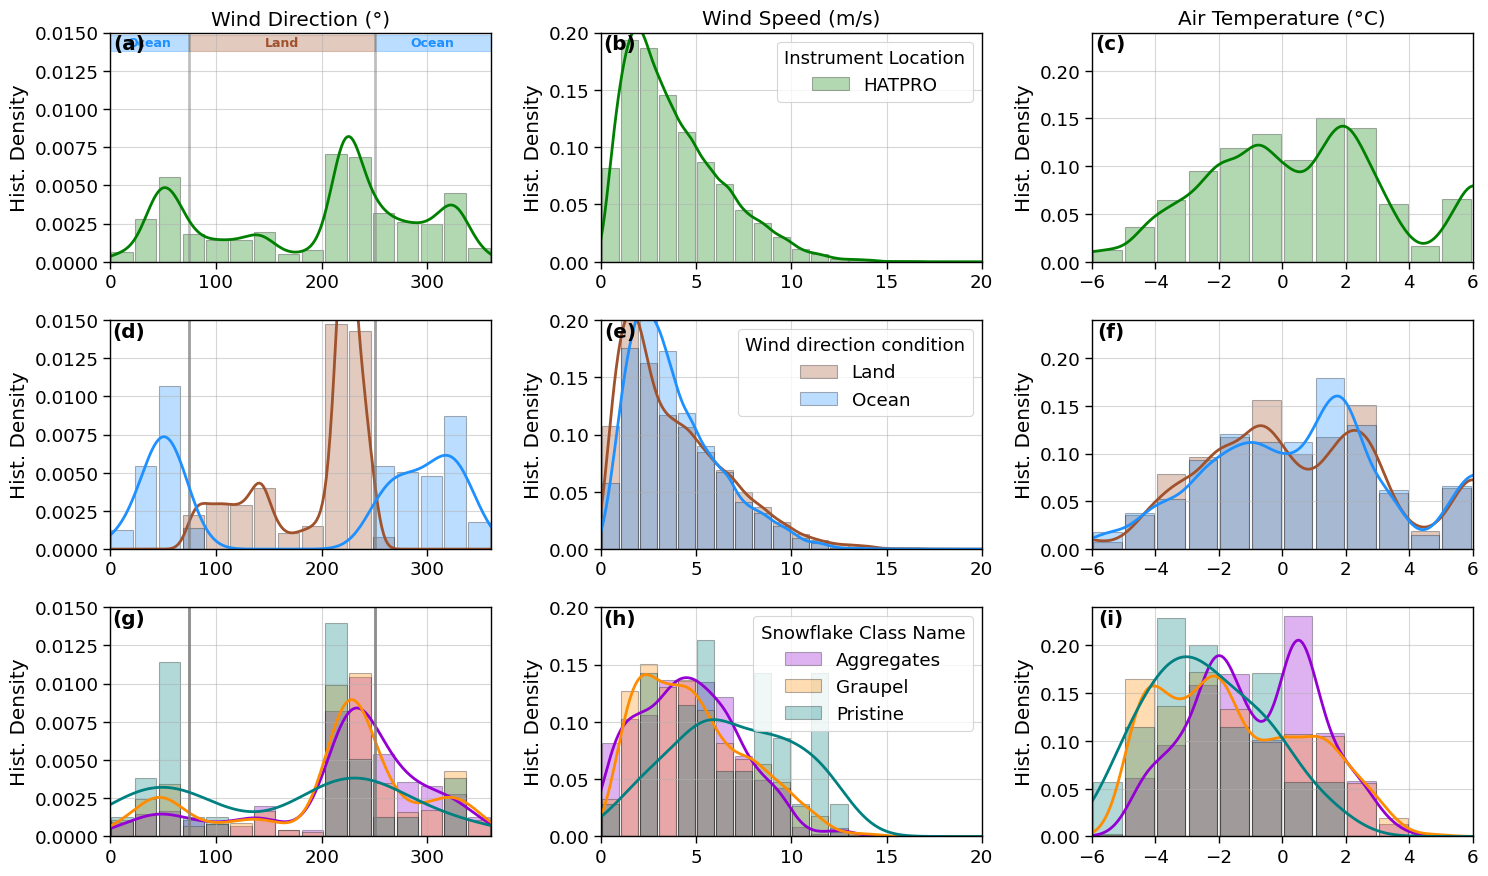

In [24]:
ylims = {'wind_direction': [0,0.015], 'wind_speed': [0, 0.2], 'air_temperature': [0,0.24]}


# Data dicts by condition
data_dict = {
    'land': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction_land', 'wind_speed_land', 'air_temperature_land']),
    'ocean': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction_ocean', 'wind_speed_ocean', 'air_temperature_ocean'])
}

fig, axsm = plt.subplots(3, 3, figsize=(15, 9), )
axs = axsm.flatten()

fct.plt_variable_group(axs[0:3],{'HATPRO': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature']),}, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'HATPRO':'green'}, labels={'HATPRO': 'HATPRO'}, xlims=xlims, ylims=ylims, kde=True, shade_regions=shade_regions, var_units=var_units, legend_title='Instrument Location', vlines=vlines, show_titles=True)

# Data dicts by condition
data_dict = {
    'land': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction_land', 'wind_speed_land', 'air_temperature_land']),
    'ocean': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction_ocean', 'wind_speed_ocean', 'air_temperature_ocean'])
}
fct.plt_variable_group(axs[3:6], data_dict, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'land':'sienna', 'ocean':'dodgerblue'}, labels={'land':'Land', 'ocean':'Ocean'}, xlims=xlims, ylims=ylims, kde=True,  legend_title ='Wind direction condition', vlines=vlines, var_units=var_units, show_titles=False)

data_dict = {
    'aggregate': fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature'], mask=(dsx['HATPRO']['most_common_class'] =='aggregate')),
    'graupel':   fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature'], mask=(dsx['HATPRO']['most_common_class'] =='graupel')),
    'pristine':   fct.extract_clean_data(dsx['HATPRO'], ['wind_direction', 'wind_speed', 'air_temperature'], mask=(dsx['HATPRO']['most_common_class'] =='pristine'))
}
fct.plt_variable_group(axs[6:9], data_dict, ['wind_direction', 'wind_speed', 'air_temperature'], bins_dict, colors={'aggregate':'darkviolet', 'graupel':'darkorange', 'pristine':'teal'}, labels={'aggregate':'Aggregates', 'graupel':'Graupel', 'pristine':'Pristine'}, xlims=xlims, ylims=ylims, kde=True,  legend_title ='Snowflake Class Name', vlines=vlines, var_units=var_units, show_titles=False)

for i, ax in enumerate(axs):
    ax.text(0.05, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

plt.tight_layout()

# figname = f"KDE_observations/KDE_WS_AT_sf_class.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

Primary max Wind direction HATPRO: 226.13 (density=0.008)
Secondary max Wind direction HATPRO: 52.46 (density=0.005)
Primary max Wind direction land: 224.32 (density=0.022)
Secondary max Wind direction land: 141.11 (density=0.004)
Primary max Wind direction ocean: 50.65 (density=0.007)
Secondary max Wind direction ocean: 316.58 (density=0.006)
Primary max Wind direction aggregate: 233.37 (density=0.008)
Secondary max Wind direction aggregate: 48.84 (density=0.001)
Primary max Wind direction graupel: 227.94 (density=0.009)
Secondary max Wind direction graupel: 320.20 (density=0.003)
Primary max Wind direction pristine: 231.56 (density=0.004)
Secondary max Wind direction pristine: 48.84 (density=0.003)
Primary max Wind direction cold: 227.94 (density=0.008)
Secondary max Wind direction cold: 48.84 (density=0.005)
Primary max Wind direction warm: 226.13 (density=0.008)
Secondary max Wind direction warm: 54.27 (density=0.004)
Primary max Wind speed HATPRO: 1.91 (density=0.204)
Secondary ma

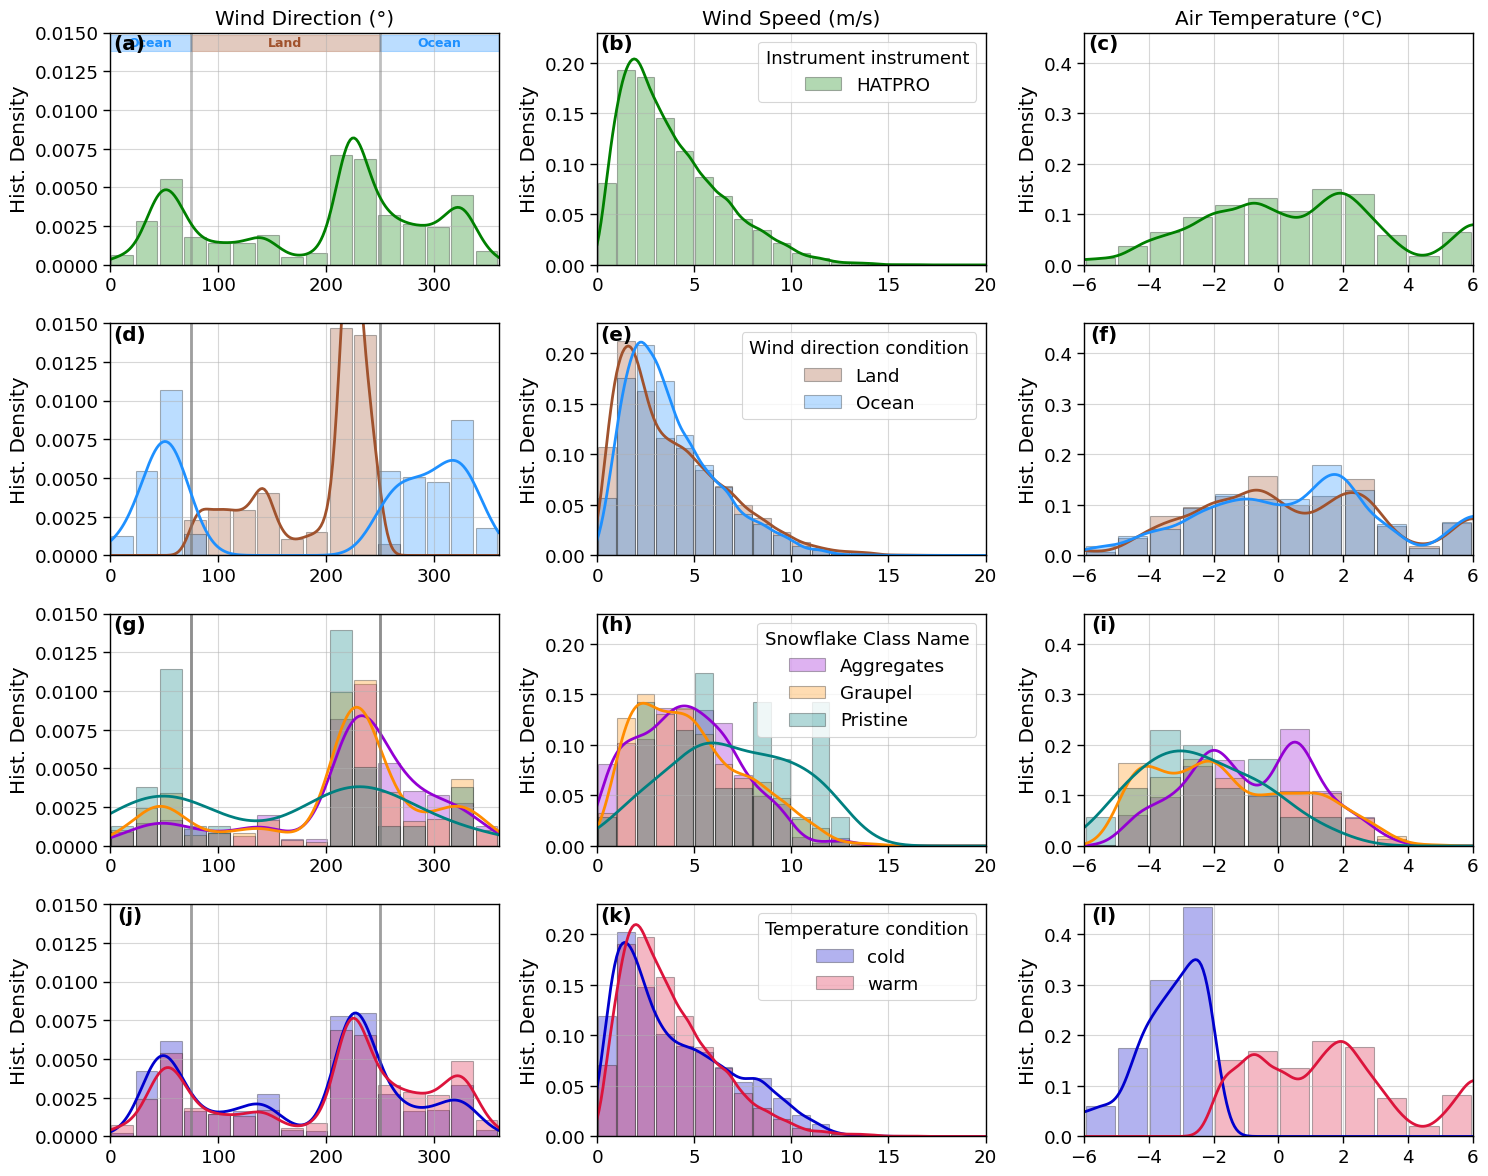

In [25]:
ylims = {'wind_direction': [0,0.015], 'wind_speed': [0, 0.23], 'air_temperature': [0,0.46]}
instrument = 'HATPRO'
kde_vars = fct.plt_kde_WD_WD_2TM_land_ocean_sf_class_cold_warm(dsx[instrument], instrument, xlims, ylims, bins_dict, shade_regions, var_units, vlines)
# figname = f"KDE_observations/KDE_WD_WS_AT_{instrument}.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)


wind_direction_ds[instrument] = xr.Dataset(kde_vars['wind_direction'])
wind_speed_ds[instrument]     = xr.Dataset(kde_vars['wind_speed'])
air_temperature_ds[instrument] = xr.Dataset(kde_vars['air_temperature'])

fct.find_primary_secondary_max(wind_direction_ds[instrument], wind_speed_ds[instrument], air_temperature_ds[instrument])

Primary max Wind direction Airport: 186.33 (density=0.005)
Secondary max Wind direction Airport: 260.50 (density=0.004)
Primary max Wind direction land: 180.90 (density=0.010)
Secondary max Wind direction land: 144.72 (density=0.006)
Primary max Wind direction ocean: 282.21 (density=0.007)
Secondary max Wind direction ocean: 39.80 (density=0.003)
Primary max Wind direction aggregate: 189.95 (density=0.008)
Secondary max Wind direction aggregate: 274.97 (density=0.005)
Primary max Wind direction graupel: 215.28 (density=0.005)
Secondary max Wind direction graupel: 32.56 (density=0.001)
Primary max Wind direction pristine: 247.84 (density=0.004)
No secondary max for Wind direction pristine
Primary max Wind direction cold: 186.33 (density=0.006)
Secondary max Wind direction cold: 345.53 (density=0.002)
Primary max Wind direction warm: 264.12 (density=0.005)
Secondary max Wind direction warm: 188.14 (density=0.004)
Primary max Wind speed Airport: 6.86 (density=0.105)
No secondary max for W

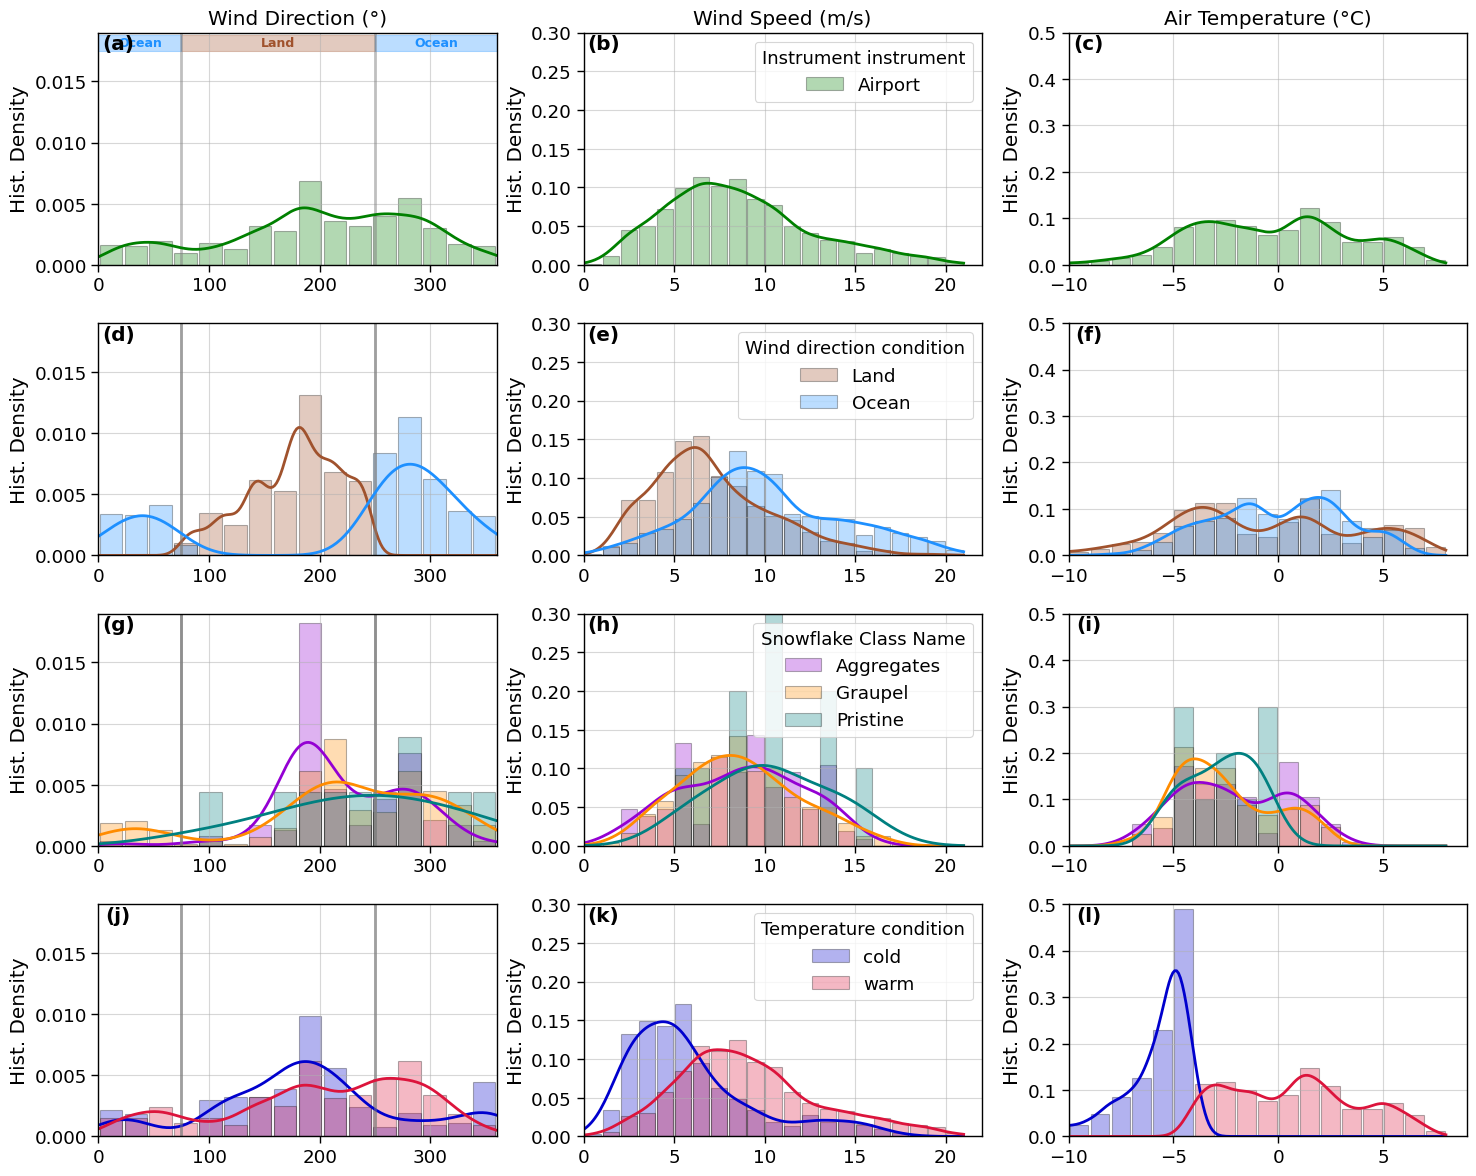

In [26]:
instrument = 'Airport'

for loc in [instrument]:

    # Compute the boolean indexer for air temperature first
    warm_condition = (dsx[loc]['air_temperature'] >= -4.).compute() # based on the graupel/aggregate KDE
    cold_condition = (dsx[loc]['air_temperature'] < -4.).compute()
    
    for var in var_names:
        if var in dsx[loc]:
            dsx[loc][var+'_cold'] = dsx[loc][var].where(cold_condition, drop=True)
            dsx[loc][var+'_warm'] = dsx[loc][var].where(warm_condition, drop=True)
        
        # print(f"{loc}, {var}, All: {dsx[loc][var].count().values}, Cold: {dsx[loc][var+'_cold'].count().values}, Warm: {dsx[loc][var+'_warm'].count().values}")
        
        
bins_dict = {'wind_direction': wd_bins, 'wind_speed': np.arange(0,22), 'air_temperature': np.arange(-10,9,1)}
xlims = {'wind_direction': [0, 360], 'wind_speed': [0,22], 'air_temperature': [-10,9]}
ylims = {'wind_direction': [0,0.019], 'wind_speed': [0, 0.3], 'air_temperature': [0,0.5]}

kde_vars = fct.plt_kde_WD_WD_2TM_land_ocean_sf_class_cold_warm(dsx[instrument], instrument, xlims, ylims, bins_dict, shade_regions, var_units, vlines)
# figname = f"KDE_observations/KDE_WD_WS_AT_{instrument}.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)


wind_direction_ds[instrument] = xr.Dataset(kde_vars['wind_direction'])
wind_speed_ds[instrument]     = xr.Dataset(kde_vars['wind_speed'])
air_temperature_ds[instrument] = xr.Dataset(kde_vars['air_temperature'])


fct.find_primary_secondary_max(wind_direction_ds[instrument], wind_speed_ds[instrument], air_temperature_ds[instrument])

Primary max Wind direction HATPRO_Airport_10min: 182.71 (density=0.005)
Secondary max Wind direction HATPRO_Airport_10min: 255.08 (density=0.004)
Primary max Wind direction land: 180.90 (density=0.012)
Secondary max Wind direction land: 209.85 (density=0.008)
Primary max Wind direction ocean: 278.59 (density=0.008)
Secondary max Wind direction ocean: 41.61 (density=0.004)
Primary max Wind direction aggregate: 189.95 (density=0.009)
Secondary max Wind direction aggregate: 274.97 (density=0.005)
Primary max Wind direction graupel: 213.47 (density=0.007)
Secondary max Wind direction graupel: 293.07 (density=0.004)
Primary max Wind direction pristine: 32.56 (density=0.003)
Secondary max Wind direction pristine: 218.89 (density=0.003)
Primary max Wind direction cold: 213.47 (density=0.006)
Secondary max Wind direction cold: 144.72 (density=0.004)
Primary max Wind direction warm: 180.90 (density=0.006)
Secondary max Wind direction warm: 293.07 (density=0.005)
Primary max Wind speed HATPRO_Ai

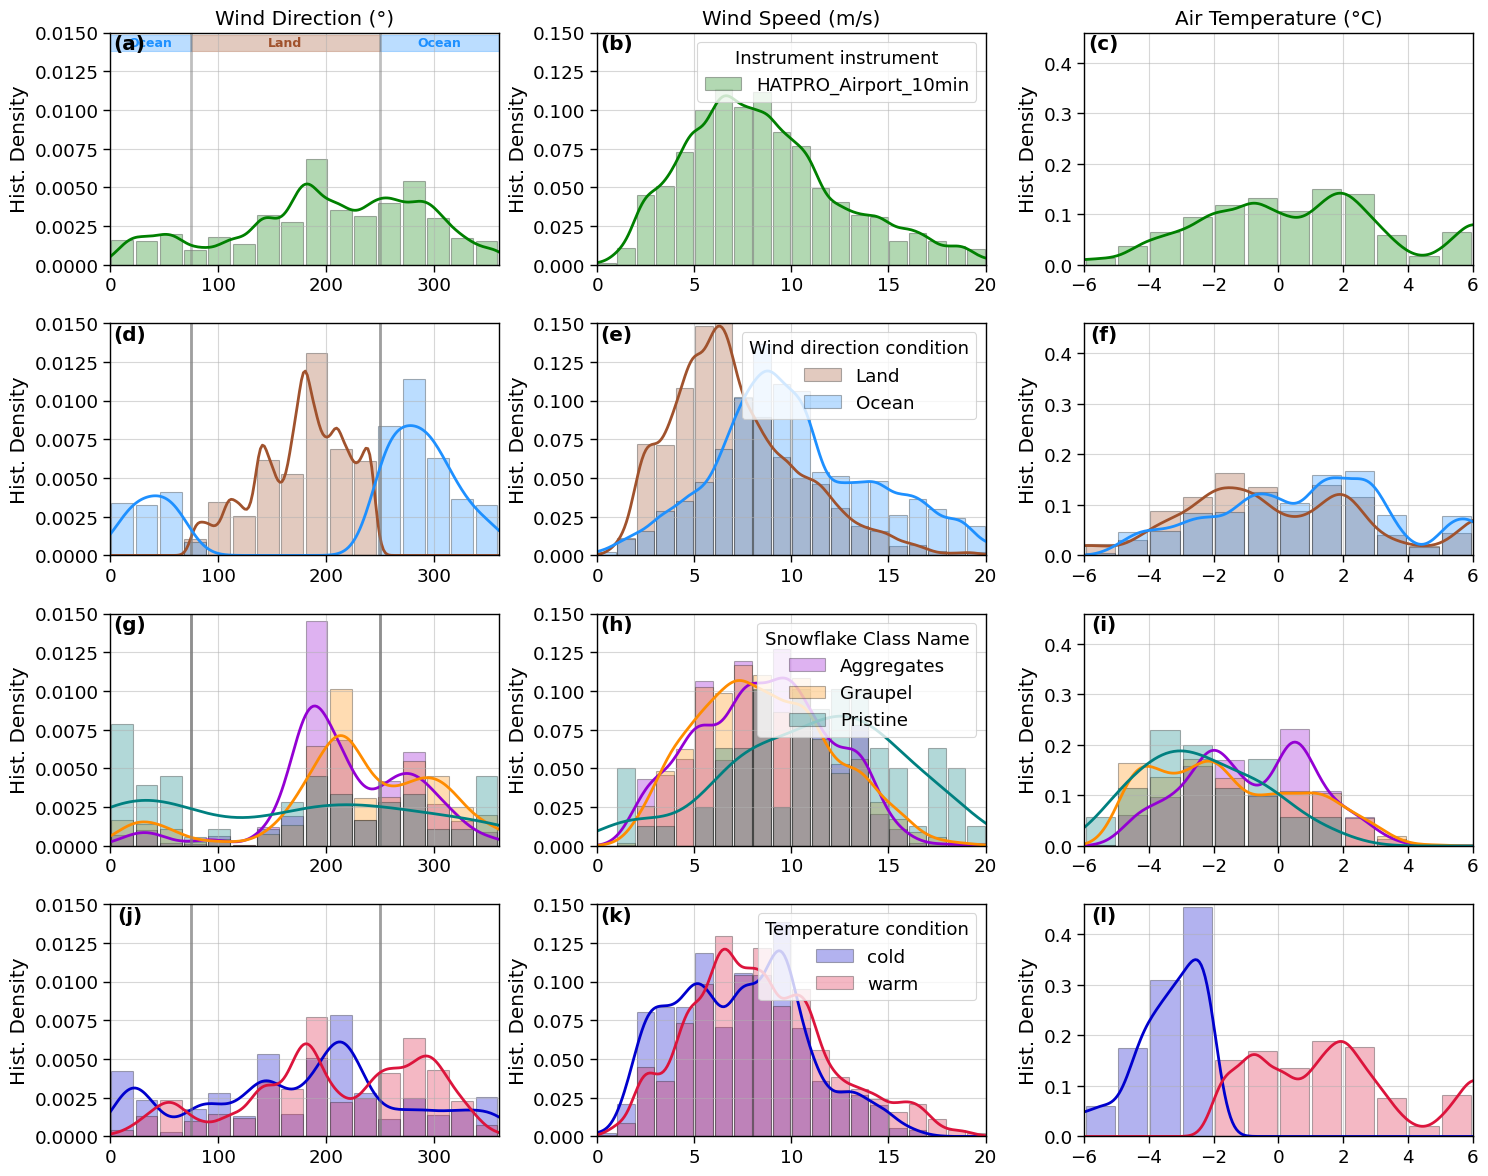

In [27]:
instrument = 'HATPRO_Airport_10min'

bins_dict = {'wind_direction': wd_bins, 'wind_speed': ws_bins, 'air_temperature': at_bins}
xlims = {'wind_direction': [0, 360], 'wind_speed': [0,20], 'air_temperature': [-6,6]}
ylims = {'wind_direction': [0,0.015], 'wind_speed': [0, 0.15], 'air_temperature': [0,0.46]}



kde_vars = fct.plt_kde_WD_WD_2TM_land_ocean_sf_class_cold_warm(dsx[instrument], instrument, xlims, ylims, bins_dict, shade_regions, var_units, vlines)
# figname = f"KDE_observations/KDE_WD_WS_AT_{instrument}.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)


wind_direction_ds[instrument] = xr.Dataset(kde_vars['wind_direction'])
wind_speed_ds[instrument]     = xr.Dataset(kde_vars['wind_speed'])
air_temperature_ds[instrument] = xr.Dataset(kde_vars['air_temperature'])

fct.find_primary_secondary_max(wind_direction_ds[instrument], wind_speed_ds[instrument], air_temperature_ds[instrument])

## Reprocess temperature categories (use e.g., 25th /75th percentile)

Primary max Wind direction HATPRO: 226.13 (density=0.008)
Secondary max Wind direction HATPRO: 52.46 (density=0.005)
Primary max Wind direction cold: 227.94 (density=0.008)
Secondary max Wind direction cold: 48.84 (density=0.005)
Primary max Wind direction warm: 226.13 (density=0.008)
Secondary max Wind direction warm: 54.27 (density=0.004)
Primary max Wind direction T_q25: 227.94 (density=0.008)
Secondary max Wind direction T_q25: 48.84 (density=0.005)
Primary max Wind direction T_q75: 226.13 (density=0.007)
Secondary max Wind direction T_q75: 48.84 (density=0.004)
Primary max Wind speed HATPRO: 1.91 (density=0.204)
Secondary max Wind speed HATPRO: 15.38 (density=0.000)
Primary max Wind speed cold: 1.41 (density=0.192)
Secondary max Wind speed cold: 7.94 (density=0.057)
Primary max Wind speed warm: 2.01 (density=0.210)
Secondary max Wind speed warm: 13.17 (density=0.002)
Primary max Wind speed T_q25: 1.51 (density=0.197)
Secondary max Wind speed T_q25: 8.04 (density=0.052)
Primary max

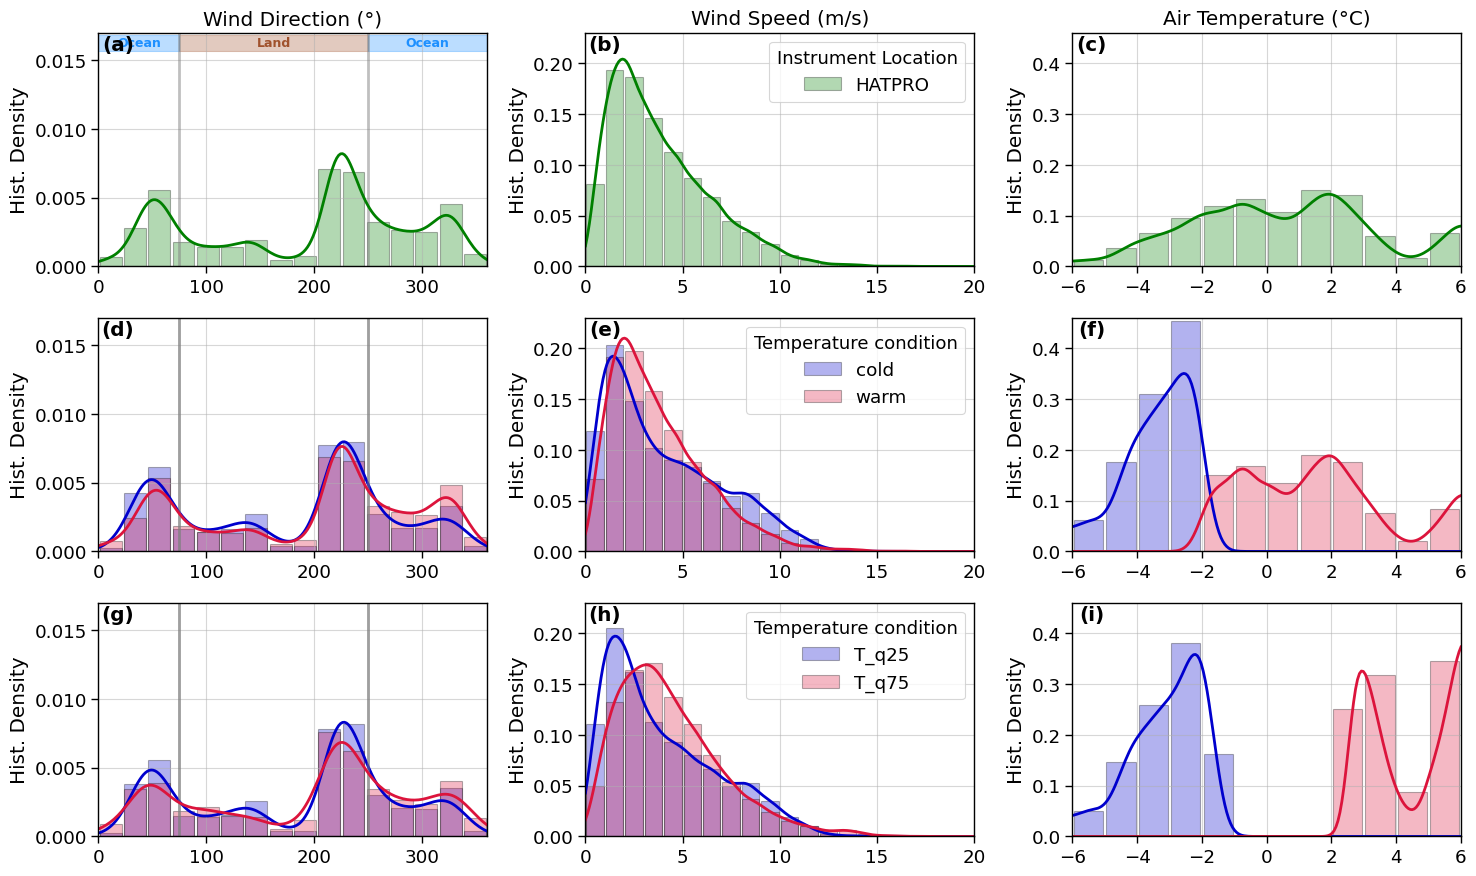

In [28]:
instrument = 'HATPRO'

xlims = {'wind_direction': [0, 360], 'wind_speed': [0,20], 'air_temperature': [-6,6]}
ylims = {'wind_direction': [0,0.017], 'wind_speed': [0, 0.23], 'air_temperature': [0,0.46]}

kde_vars = fct.plt_kde_WD_WD_2TM_cold_warm_Tq25T_q75(dsx[instrument], instrument, xlims, ylims, bins_dict, shade_regions, var_units, vlines)

# figname = f"KDE_observations/KDE_WD_WS_AT_2m_temp_quantile_{instrument}.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

wind_direction_ds[instrument] = xr.Dataset(kde_vars['wind_direction'])
wind_speed_ds[instrument]     = xr.Dataset(kde_vars['wind_speed'])
air_temperature_ds[instrument] = xr.Dataset(kde_vars['air_temperature'])

fct.find_primary_secondary_max(wind_direction_ds[instrument], wind_speed_ds[instrument], air_temperature_ds[instrument])

Primary max Wind direction Airport: 186.33 (density=0.005)
Secondary max Wind direction Airport: 260.50 (density=0.004)
Primary max Wind direction cold: 186.33 (density=0.006)
Secondary max Wind direction cold: 345.53 (density=0.002)
Primary max Wind direction warm: 264.12 (density=0.005)
Secondary max Wind direction warm: 188.14 (density=0.004)
Primary max Wind direction T_q25: 191.76 (density=0.006)
Secondary max Wind direction T_q25: 345.53 (density=0.002)
Primary max Wind direction T_q75: 249.65 (density=0.012)
Secondary max Wind direction T_q75: 182.71 (density=0.006)
Primary max Wind speed Airport: 6.86 (density=0.105)
No secondary max for Wind speed Airport
Primary max Wind speed cold: 4.43 (density=0.148)
Secondary max Wind speed cold: 13.30 (density=0.021)
Primary max Wind speed warm: 7.39 (density=0.112)
No secondary max for Wind speed warm
Primary max Wind speed T_q25: 4.43 (density=0.126)
No secondary max for Wind speed T_q25
Primary max Wind speed T_q75: 7.70 (density=0.10

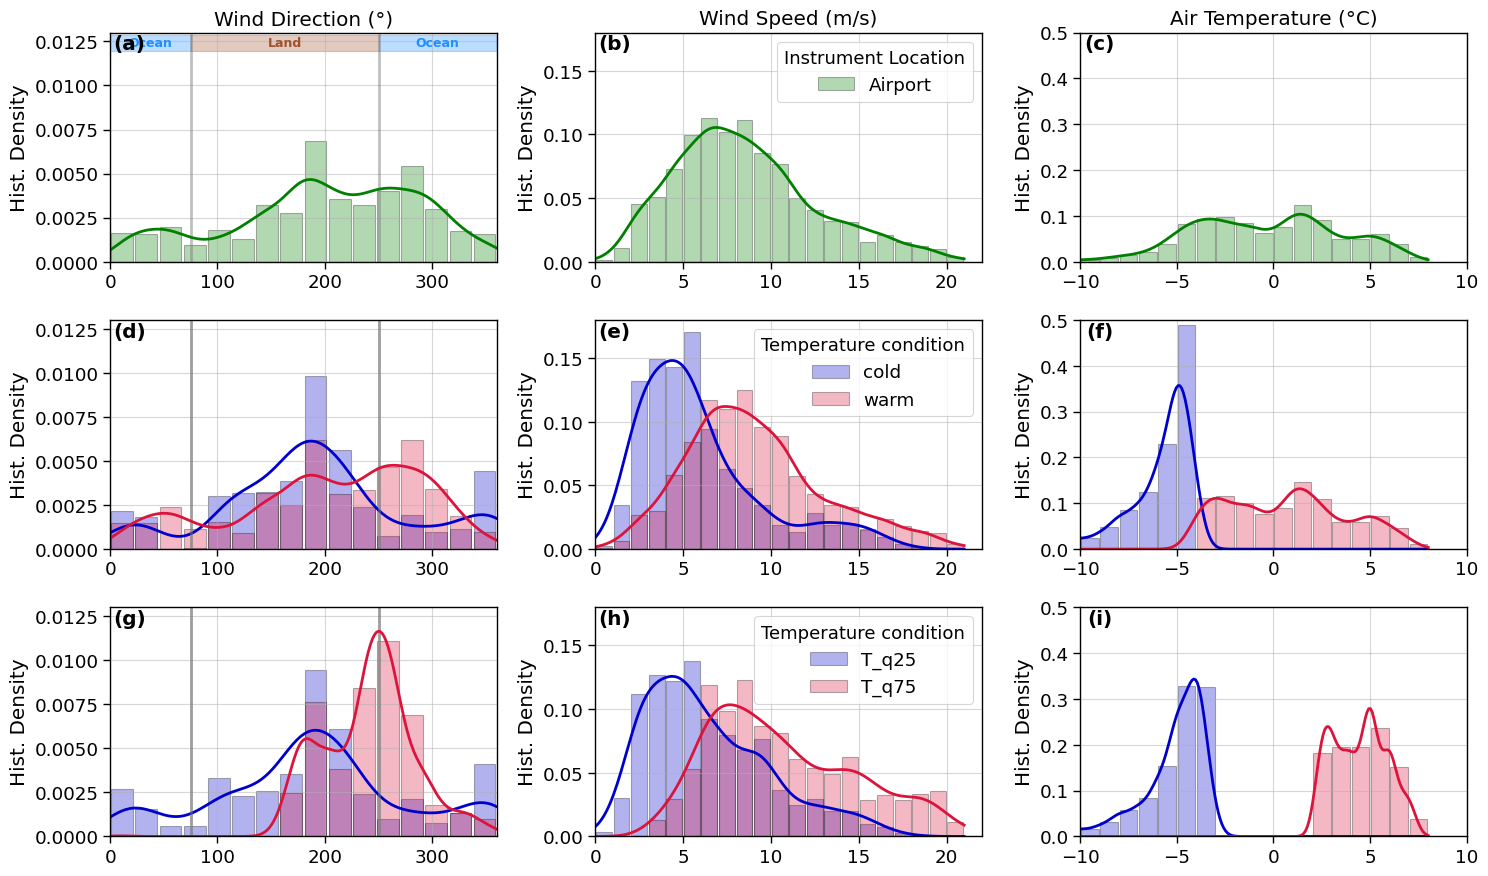

In [29]:
bins_dict = {'wind_direction': wd_bins, 'wind_speed': np.arange(0,22), 'air_temperature': np.arange(-10,9,1)}
xlims = {'wind_direction': [0, 360], 'wind_speed': [0,22], 'air_temperature': [-10,10]}
ylims = {'wind_direction': [0,0.013], 'wind_speed': [0, 0.18], 'air_temperature': [0,0.5]}
instrument = 'Airport'
kde_vars = fct.plt_kde_WD_WD_2TM_cold_warm_Tq25T_q75(dsx[instrument], instrument, xlims, ylims, bins_dict, shade_regions, var_units, vlines)

# figname = f"KDE_observations/KDE_WD_WS_AT_2m_temp_quantile_{instrument}.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

wind_direction_ds[instrument] = xr.Dataset(kde_vars['wind_direction'])
wind_speed_ds[instrument]     = xr.Dataset(kde_vars['wind_speed'])
air_temperature_ds[instrument] = xr.Dataset(kde_vars['air_temperature'])

fct.find_primary_secondary_max(wind_direction_ds[instrument], wind_speed_ds[instrument], air_temperature_ds[instrument])

Primary max Wind direction HATPRO_Airport_10min: 182.71 (density=0.005)
Secondary max Wind direction HATPRO_Airport_10min: 255.08 (density=0.004)
Primary max Wind direction cold: 213.47 (density=0.006)
Secondary max Wind direction cold: 144.72 (density=0.004)
Primary max Wind direction warm: 180.90 (density=0.006)
Secondary max Wind direction warm: 293.07 (density=0.005)
Primary max Wind direction T_q25: 211.66 (density=0.006)
Secondary max Wind direction T_q25: 146.53 (density=0.004)
Primary max Wind direction T_q75: 253.27 (density=0.010)
Secondary max Wind direction T_q75: 180.90 (density=0.008)
Primary max Wind speed HATPRO_Airport_10min: 6.65 (density=0.109)
Secondary max Wind speed HATPRO_Airport_10min: 18.36 (density=0.012)
Primary max Wind speed cold: 9.39 (density=0.120)
Secondary max Wind speed cold: 5.17 (density=0.099)
Primary max Wind speed warm: 6.54 (density=0.121)
Secondary max Wind speed warm: 10.24 (density=0.091)
Primary max Wind speed T_q25: 9.39 (density=0.116)
Sec

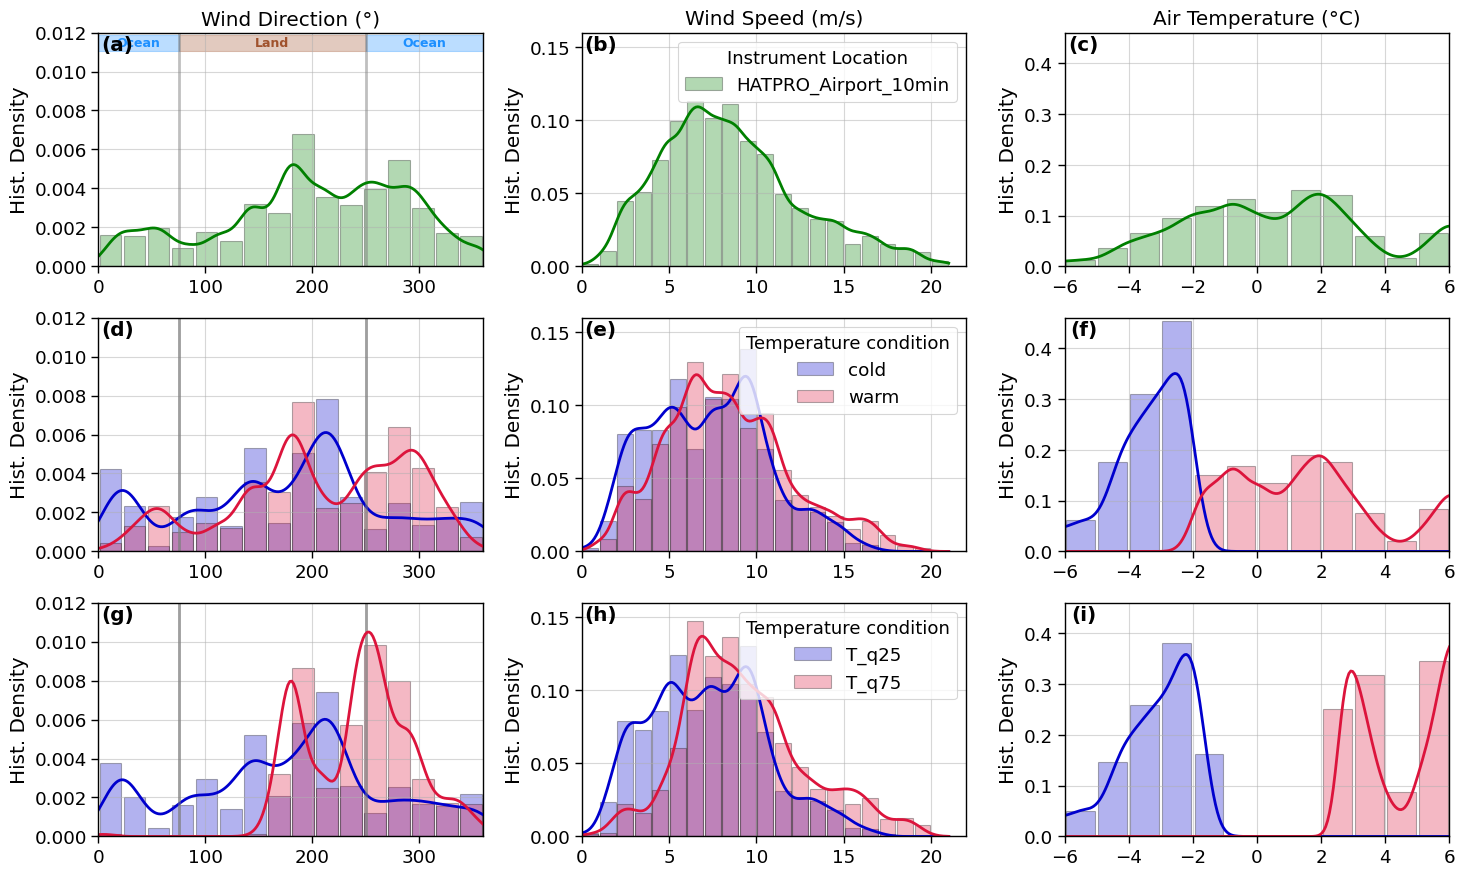

In [30]:
instrument = 'HATPRO_Airport_10min'

bins_dict = {'wind_direction': wd_bins, 'wind_speed': np.arange(0,22), 'air_temperature': at_bins}
xlims = {'wind_direction': [0, 360], 'wind_speed': [0,22], 'air_temperature': [-6,6]}
ylims = {'wind_direction': [0,0.012], 'wind_speed': [0, 0.16], 'air_temperature': [0,0.46]}

kde_vars = fct.plt_kde_WD_WD_2TM_cold_warm_Tq25T_q75(dsx[instrument], instrument, xlims, ylims, bins_dict, shade_regions, var_units, vlines)

# figname = f"KDE_observations/KDE_WD_WS_AT_2m_temp_quantile_{instrument}.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)

wind_direction_ds[instrument] = xr.Dataset(kde_vars['wind_direction'])
wind_speed_ds[instrument]     = xr.Dataset(kde_vars['wind_speed'])
air_temperature_ds[instrument] = xr.Dataset(kde_vars['air_temperature'])

fct.find_primary_secondary_max(wind_direction_ds[instrument], wind_speed_ds[instrument], air_temperature_ds[instrument])

## Combine temperature categories and wind direction categories, which might point to CAO or synoptic drivers

Use the temperature thresholds based on T_q25 and T_q75.
HATPRO_Airport_10min: Temperature 25th percentile = -1.69, 75th percentile =2.56

Then find the intersections between the wind direction KDEs which are defined with the following max.
- Primary max Wind direction T_q25: 211.66 (density=0.006)
- Secondary max Wind direction T_q25: 146.53 (density=0.004)
- Primary max Wind direction T_q75: 253.27 (density=0.010)
- Secondary max Wind direction T_q75: 180.90 (density=0.008)
  

  




In [31]:
# ---- Find the intersection between the two wind direction KDEs to seperate the wind and associated values
x_vals = wind_direction_ds['HATPRO_Airport_10min']['x']
# Difference between wind direction KDE lines
diff = (wind_direction_ds['HATPRO_Airport_10min']['T_q25'] - wind_direction_ds['HATPRO_Airport_10min']['T_q75']).values # Use NumPy array to simplify ops

# Sign of difference
sign_diff = np.sign(diff)

# Find true sign changes only (ignore consecutive True regions)
sign_change = np.where(sign_diff[1:] != sign_diff[:-1])[0] #first index of each transition.

intersections = []
segments = []

for i in sign_change:
    x0, x1 = x_vals[i], x_vals[i + 1]
    y0, y1 = diff[i], diff[i + 1]

    # Linear interpolation to find crossing point
    if y1 != y0:  # Avoid divide-by-zero
        x_cross = x0 - y0 * (x1 - x0) / (y1 - y0)
        intersections.append(x_cross.values)
        segments.append(((x0.values, x1.values), (y0, y1)))
        
for (x0, x1), (y0, y1) in segments:
    print(f"Segment: x=({x0:.2f}, {x1:.2f}) | y=({y0:.4f}, {y1:.4f})")

Segment: x=(162.81, 164.62) | y=(0.0004, -0.0002)
Segment: x=(193.57, 195.38) | y=(-0.0002, 0.0004)
Segment: x=(227.94, 229.75) | y=(0.0008, -0.0000)
Segment: x=(343.72, 345.53) | y=(-0.0001, 0.0000)


In [32]:
for (WD1, WD2), _ in segments:
    _mean =  np.mean([WD1, WD2])
    print(WD1, WD2, round(_mean/5)*5)

162.8140703517588 164.62311557788945 165
193.5678391959799 195.37688442211055 195
227.93969849246233 229.74874371859298 230
343.71859296482415 345.5276381909548 345


###  Encode Features for Clustering

- Transform wind direction to sin/cos for circular continuity.
- Encode snowflake classes as integers.

Interpret the Clusters

Look for:
- Clusters with cold temps + northerly winds + graupel dominance
- Clusters with warm temps + southerly winds + aggregates

In [33]:
# # Convert wind direction (°) to sin/cos
# df['wind_sin'] = np.sin(np.deg2rad(df['wind_direction_filled']))
# df['wind_cos'] = np.cos(np.deg2rad(df['wind_direction_filled']))
# from sklearn.preprocessing import LabelEncoder
# from sklearn.cluster import KMeans
# # Encode snowflake classes numerically
# le = LabelEncoder()
# df['snowflake_encoded'] = le.fit_transform(df['snowflake_class'])
# # Apply K-Means Clustering
# X = df[['air_temperature', 'wind_sin', 'wind_cos', 'snowflake_encoded']]
# # Choose number of clusters (try 3–6)
# kmeans = KMeans(n_clusters=6, random_state=42)
# df['cluster'] = kmeans.fit_predict(X)
# # Visualize the Clusters
# # 2D Scatter Plot: Temperature vs Wind Direction (Colored by Cluster)
# plt.figure(figsize=(8, 6))
# sc = plt.scatter(df['air_temperature'], df['wind_direction_filled'], c=df['cluster'], cmap='tab10', alpha=0.7)
# plt.xlabel('HATPRO Temperature (°C)')
# plt.ylabel('Wind Direction (°)')
# plt.colorbar(sc, label='Cluster')
# plt.title('Clustering of Snowflake Events by Temp & Wind Direction')
# plt.grid(True)
# plt.show()

Consider Temporal Aggregation (Event-Based or Rolling Windows)

Instead of pointwise comparisons:

    Define events (e.g., periods with same snowflake class for ≥10 min)

    Average wind + temp over that window

    Then classify

In [34]:
def frequency_sf_class_per_bin(bins, dbins, var_name, dsx, particle_vars):

    
    # Define bins (e.g., for temperature -6 to +6 °C with 1°C steps)
    bin_labels = bins[:-1] + dbins # centers for plotting
    
    # Flatten variable data and particle data to 1D
    var = dsx[var_name].values.flatten()
    mask = ~np.isnan(var)
    
    if 'wind_direction' in var_name:
        var_bin = pd.cut(var[mask] %360, bins=bins, labels=bin_labels)
    else:
        # Bin variable using pandas
        var_bin = pd.cut(var[mask], bins=bins, labels=bin_labels)
    
    # Initialize DataFrame to hold results
    df = pd.DataFrame({'var_bin': var_bin})
    
    # For each particle class, flatten and apply mask
    for var_class in particle_vars:
        class_data = dsx[var_class].values.flatten()
        df[var_class] = class_data[mask]
        
    # Group by variable bin and sum each class
    grouped = df.groupby('var_bin')[particle_vars].sum()
    
    # Optional: normalize row-wise to get relative frequency
    relative_freq = grouped.div(grouped.sum(axis=1), axis=0)
    relative_freq.where(relative_freq != 0, np.nan, inplace=True) # remove 0 from relative frequency
    
    # Transpose to get snowflake classes on y-axis
    freq_matrix = relative_freq.T  # shape: (snowflake class, variable bins)
    return freq_matrix

In [35]:
def plt_sf_class_vs_var_bins(freq_matrix, x_label):
    
    fig, ax = plt.subplots(figsize=(15, 4))

    # Define discrete levels
    bounds = np.arange(0., 1.01, 0.1)
    norm = BoundaryNorm(boundaries=bounds, ncolors=256)
    # cmap = plt.get_cmap('viridis')
    cmap = cm.hawaii_r

    # Plot using imshow
    cax = ax.imshow(freq_matrix.values, aspect='auto', cmap=cmap, origin='lower', norm=norm)

    # Add text annotations
    for i in range(freq_matrix.shape[0]):  # y-axis (snowflake class)
        for j in range(freq_matrix.shape[1]):  # x-axis (temperature bin)
            value = freq_matrix.iloc[i, j]
            if not np.isnan(value) and value != 0.0:  # Skip NaNs and zeros
                text_color = "white" if value > 0.5 else "black"
                # ax.text(j, i, f"{value:.2f}", ha='center', va='center', color=text_color, fontsize=8)
                ax.text(j, i, f"{value:.0%}", ha='center', va='center', color=text_color, fontsize=8)


    # Set ticks
    ax.set_xticks(np.arange(len(freq_matrix.columns)))
    ax.set_xticklabels([f"{x:.1f}" for x in freq_matrix.columns], rotation=45)
    ax.set_xlabel(x_label)

    ax.set_yticks(np.arange(len(freq_matrix.index)))
    ax.set_yticklabels(freq_matrix.index)
    # ax.set_ylabel("Snowflake Class")

    # Add colorbar
    cbar = fig.colorbar(cax, ax=ax, ticks=bounds)
    cbar.ax.set_yticklabels([f"{int(l*100)}%" for l in bounds])
    cbar.set_label("Relative Frequency")

    plt.title(f"Snowflake Class Frequency vs {x_label}")
    plt.tight_layout()
    # plt.show()


In [36]:
temp_bins = np.arange(-6,6,1) # edges

temp_matrix = frequency_sf_class_per_bin(temp_bins, 0.5, 'air_temperature', dsx_at, particle_vars)

plt_sf_class_vs_var_bins(temp_matrix, "2m Air Temperature (°C)")
# figname = f"sf_class_frequ/sf_class_vs_temp.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)


NameError: name 'dsx_at' is not defined

In [ ]:
# wd_bins = np.arange(0,365,90) # edges
# wd_matrix = frequency_sf_class_per_bin(wd_bins, 45, 'wind_direction', dsx)
# plt_sf_class_vs_var_bins(wd_matrix, "Wind Direction (°)")
# figname = f"sf_class_frequ/sf_class_vs_wd.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
# ws_bins = np.arange(0,20,1) # edges
# ws_matrix = frequency_sf_class_per_bin(ws_bins, .5, 'wind_speed', dsx)
# plt_sf_class_vs_var_bins(ws_matrix, "Wind Speed (m/s)")
# figname = f"sf_class_frequ/sf_class_vs_ws.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
# wd_bins = np.arange(0,365,45) # edges
# wd_matrix = frequency_sf_class_per_bin(wd_bins, 22.5, 'wind_direction_land', dsx)
# plt_sf_class_vs_var_bins(wd_matrix, "Wind Direction (°) 'land'")
# figname = f"sf_class_frequ/sf_class_vs_wd_land.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
# wd_bins = np.arange(0,365,45) # edges
# wd_matrix = frequency_sf_class_per_bin(wd_bins, 22.5, 'wind_direction_ocean', dsx)
# plt_sf_class_vs_var_bins(wd_matrix, "Wind Direction (°) 'ocean'")
# figname = f"sf_class_frequ/sf_class_vs_wd_ocean.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
# temp_bins = np.arange(-6,6,2) # edges

# temp_matrix = frequency_sf_class_per_bin(temp_bins, 1, 'air_temperature_land', dsx)
# plt_sf_class_vs_var_bins(temp_matrix, "2m Air Temperature (°C) 'land'")
# figname = f"sf_class_frequ/sf_class_vs_temp_land.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
# temp_bins = np.arange(-6,6,2) # edges

# temp_matrix = frequency_sf_class_per_bin(temp_bins, 1, 'air_temperature_ocean', dsx)
# plt_sf_class_vs_var_bins(temp_matrix, "2m Air Temperature (°C) 'ocean'")
# figname = f"sf_class_frequ/sf_class_vs_temp_ocean.png"
# plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)